# Preprocess and baseline comparison

Runs the whole baseline from raw frames to the comparison chart:

1. **Preprocess** (`preprocess.py`): sample 20 frames per video, split the videos into train/validation/test, and turn every sampled frame into a 768-number MegaDescriptor-S-224 embedding.
2. **Baseline** (`core_objective.py`): average each video's frame embeddings, measure Rank-1 accuracy by matching each validation video to its most similar training video (the test split stays held out), and plot the result next to other wildlife datasets.

## 0. Imports and setup

All imports are here. Notebooks live in `notebooks/`, but the code and data paths are relative to the repo folder, so this cell first switches to the repo folder and lets Python find the project files, then imports them. Copy the path setup into any new notebook in `notebooks/`.

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo folder (the first folder up that has requirements.txt)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
os.chdir(ROOT)                  # so paths like data/splits work
sys.path.insert(0, str(ROOT))   # so the project files below can be imported

from core import preprocess
from core import core_objective

## 1. Preprocess: frames → embeddings

`run_pipeline` does, in order:

1. Find every image in `data/PolarBearVidID/` and read its bear, video and frame number from the filename (138,363 frames).
2. Keep 20 evenly spaced frames per video (1,431 videos → 28,620 frames).
3. Split the **videos** 70/15/15 into train/validation/test, stratified by bear, so all frames of a video stay in one split (1,001 / 215 / 215 videos).
4. Save the splits to `data/splits/train.csv`, `validation.csv`, `test.csv`.
5. Load MegaDescriptor-S-224 (downloaded from Hugging Face the first time; frozen, no training).
6. Run every sampled frame through it and save the embeddings, shape `(28620, 768)`, with their labels to `data/polarbear_embeddings.npz`.

Uses the GPU if one is available, otherwise the CPU.

In [2]:
preprocess.run_pipeline("data/PolarBearVidID", csv_out_dir="data/splits")

[12:33:54][INFO] Splits (data/splits) and embeddings (data/polarbear_embeddings.npz) already exist, skipping preprocessing (pass overwrite=True to redo it)


## 2. Baseline: Rank-1 accuracy and comparison chart

- `aggregate_video_embeddings` averages each video's 20 frame embeddings into one video embedding (1,431 × 768).
- `calculate_rank1_accuracy` uses the training videos as the **gallery** and the validation videos as **queries** (the test split stays held out until the final evaluation). Each validation video is matched to its most similar training video (cosine similarity); it counts as correct if that video shows the same bear. Result: **88.84%** (191 of 215 validation videos).
- `plot_comparison_results` saves `results/core_comparison_table.csv` and `results/core_comparison_chart.png`, comparing our result with MegaDescriptor-S-224's reported results on 29 other wildlife datasets (Table 5 of the paper).

### Where the comparison numbers come from

The other datasets' accuracies in `plot_comparison_results` come from **Table 5** of the MegaDescriptor paper ([PDF](https://arxiv.org/pdf/2311.09118)). We run **MegaDescriptor-S-224**, so the chart uses the **S-224** column (second).

![Table 5 of the MegaDescriptor paper: accuracy by model size](../docs/images/megadescriptor_table5.png)

*Source: Čermák et al., "WildlifeDatasets: An open-source toolkit for animal re-identification", WACV 2024, Table 5.*

[12:33:55][INFO] Polar Bear Rank-1 Accuracy: 88.84% (191/215 validation videos)


[12:33:55][INFO] Polar bears rank 12 of 30 datasets


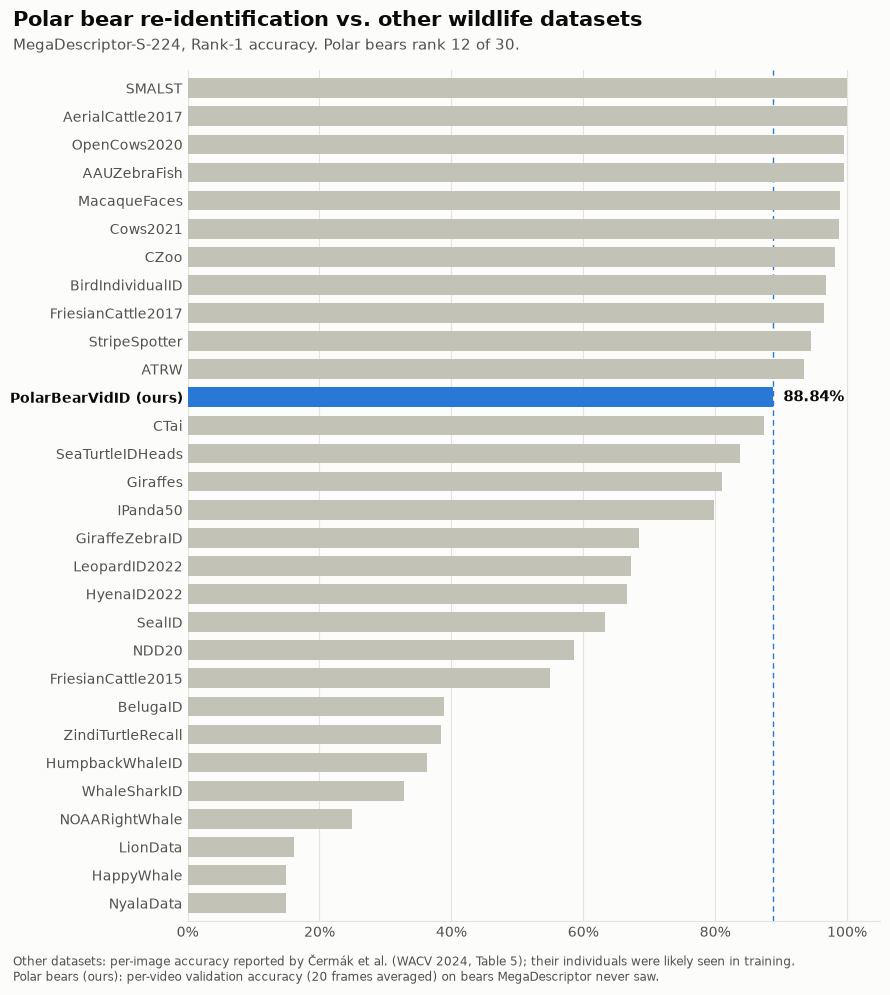

In [3]:
seq_embs, seq_df = core_objective.aggregate_video_embeddings("data/polarbear_embeddings.npz")
pb_acc = core_objective.calculate_rank1_accuracy(seq_embs, seq_df)
core_objective.plot_comparison_results(polar_bear_acc=pb_acc)